# Project 3: Time Series Modeling of Air Quality in Nairobi

- **Concepts**:
    - Time-Series Analysis, NoSQL (MongoDB), Lagged Regression, AR & ARMA Models.
- **Description**: 
    - This project deals with time-indexed data. Using air quality measurements from Nairobi stored in MongoDB, we query, prepare, and forecast time series data. The project builds from simple lagged regression up to Autoregressive (AR) and ARMA models

## 1.0 Prepare  

In [1]:
# import liberaries
import warnings
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px 
import pytz
from statsmodels.graphics.tsaplots import plot_acf , plot_pacf
from pymongo.mongo_client import MongoClient
from sklearn.metrics import mean_absolute_error
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.seasonal import seasonal_decompose


warnings.simplefilter(action="ignore", category=FutureWarning)



### Data Wrangling with MongoDB 

1. Connect to the local Docker container 
    - I created a local MongoDB database from the "sensors.AFRICA Air Quality Archive Nairobi" data set available at Open.Africa. I took the 12 csv files from Aug 2025 to July 2026 to mark a full year's worth of data. 
    - I proceeded to create a local MongoDB database using MongoDB in a Docker container. The 12 CSVs make up the `air_quality` database, `nairobi` collection.
        - Look at the `mongodb-creation.bash` file for steps on this.

In [8]:
# Connect to MongoDB database
client = MongoClient("mongodb://localhost:27017/")
type(client)

pymongo.synchronous.mongo_client.MongoClient

In [7]:
# to see the database names
client.list_database_names()

['admin', 'air-quality', 'config', 'local']

In [10]:
#we only need to look at the 'air-quality' database
db = client["air-quality"]

#look into the collections in the 'air=quality' database
db.list_collection_names()

['nairobi']

In [ ]:
#now we connect to the collection
nairobi_collection = db["nairobi"]
type(nairobi_collection)

pymongo.synchronous.collection.Collection

In [19]:
#the 'nairobi_collection' contains our documents (readings), we now need to see how many fields each sensor reading has
nairobi_collection.find_one()

{'_id': ObjectId('6ae260c882c8f6828eae4412'),
 'sensor_id': 4927,
 'sensor_type': 'DHT22',
 'location': 3981,
 'lat': -1.269,
 'lon': 36.819,
 'timestamp': '2025-08-01T00:03:03.447032+00:00',
 'value_type': 'humidity',
 'value': 72.9}

- We can see that each sensor reading has 9 fields (id,sensor_id,sensor_type,location,lat,lon,timestamp,value_type,and value)
- According to the Data source description, the value_type field holds five unique types (temperature,humidity,PM1,PM2.5,and PM10). In our case, we are focused on PM2.5 data which respresents the P2 readings, useful for monitoring air-quality.
    - PM2.5 represents the no. of particles smaller than 2.5 micrometers that can penetrate deeply into the lungs and bloodstream, making PM2.5 the primary metric used for health advisories, regulatory indexes (such as the AQI or PSI), and machine-learning target variables
- Note that PM10, PM1, temperature, and humidity play essential direct and supporting roles, more on this later.


In [ ]:
# Get unique sensor readings collection sites that have PM2.5 readings ("P2")
sites = nairobi_collection.distinct("location", {"value_type": "P2"})
print(f"No. of sites: {len(sites)}")
list(sites)

No. of sites: 7


[37, 76, 3966, 3967, 3981, 4013, 4014]

- The data has only 7 sites that have the PM2.5 readings. We focus on these sites as they are the only ones with the data we need.
- Lets see how many sensor readings came from each site. That way, we can select the one with the most readings and focus on that alone
    - Reason:
        - Sequential Integrity: AR models assume that the current value ($y_t$) is a direct function of its immediate past values ($y_{t-1}, y_{t-2}$, etc.). Mixing data from different geographical locations breaks this chronological chain. A reading from Site 76 is not the historical predecessor to a reading at Site 3981.
        - Timestamp Conflicts: Univariate time series models expect exactly one value per time step (a 1D vector). If you merge data from all 7 sites, you will have multiple overlapping PM2.5 readings for the exact same hour or minute.
        - Redundancy: Focusing on one high-quality sensor is computationally cheaper for modelling and highly representative of the Nairobi region, hence no need to use more than one site.

In [24]:
for site in sites:
    count = nairobi_collection.count_documents({"location": site})
    print(f"Site {site}: {count:,} documents")

Site 37: 10 documents
Site 76: 381,214 documents
Site 3966: 127,855 documents
Site 3967: 92,552 documents
Site 3981: 581,889 documents
Site 4013: 8,475 documents
Site 4014: 4,074 documents


- In this case, I chose Site 3981 since i thas the most readings, making it the most robust dataset available. Also, since it has the most data, it means the other sites have massive chronological gaps (probably due to sensor downtime, connection loss). Missing data breaks the continuous lags required by AR models. Choosing the site with the most readings minimizes the amount of synthtetic data you have to generate to fill in the gaps.
- Now that site 3981 is out focus, to create our series dataframe (y), we have to create a wrangle function that queries the MongoDB database for only values in that site(location) with P2 value_types. To make this dataframe y, we only need the value_type and timestamp fields, where the timestamp field will be made into the index, thereby creating our time series y.

In [64]:


# 2. Define the adapted wrangle function
def wrangle(collection, location=76):
    """
    Wrangles all PM2.5 (P2) data from MongoDB for a given location across all available dates.
    """
    # Use $regex to match the string timestamp starting with "2025"
    query = {
        "location": location, 
        "value_type": "P2"
    }
    
    # Pull only value and timestamp fields
    result = collection.find(
        query,
        projection={'value': 1, 'timestamp': 1, '_id': 0}
    )
    
    # Import into DataFrame
    df = pd.DataFrame(list(result))
    
    # Return empty series if no data matches the query
    if df.empty:
        return pd.Series(dtype='float64')
    
    # Convert string timestamps to actual pandas datetime objects
    df['timestamp'] = pd.to_datetime(df['timestamp'], format='mixed', utc=True)

    
    # Set the datetime column as the index
    df.set_index('timestamp', inplace=True)
    
    # Convert timezone from UTC (+00:00) to Nairobi
    df.index = df.index.tz_convert('Africa/Nairobi')

    # Sort chronologically (essential before resampling - MongoDB does not guarantee chronological order across multi-CSV imports)
    df.sort_index(inplace=True)
    
    # Convert values to float and filter out outliers (< 250)
    # ==== In air quality sensor data, readings aboe 250 are more likely to be false readings (sensor malfunctions or electronic dropouts)
    df["value"] = pd.to_numeric(df["value"], errors='coerce')
    df = df[df["value"] < 250].dropna(subset=["value"])
    
    # Rename to P2
    df.rename(columns={"value": "P2"}, inplace=True)    
    
    # Resample to 1-Hour intervals (taking the mean) and forward-fill missing hours
    y = df['P2'].resample('1h').mean().ffill()
    
    # Drop any remaining nulls 
    y.dropna(inplace=True)
    
    return y

In [66]:
y = wrangle(nairobi_collection, location=76)

print(f"Start date: {y.index.min()}")
print(f"End date:   {y.index.max()}")
print(f"Total hours: {len(y):,}")
print(y.head())


Start date: 2025-10-31 15:00:00+03:00
End date:   2026-07-27 02:00:00+03:00
Total hours: 6,444
timestamp
2025-10-31 15:00:00+03:00    18.000000
2025-10-31 16:00:00+03:00    18.000000
2025-10-31 17:00:00+03:00    16.000000
2025-10-31 18:00:00+03:00    20.809524
2025-10-31 19:00:00+03:00    32.428571
Freq: h, Name: P2, dtype: float64


## 2.0 Exploratory Data Analysis (EDA) 

- We now have the y time-series, and we can now start EDA to understand its characterictics - showcasing the distribution of P2 readings, visualizing the time-series data trends, seasonality, and autocorrelation:
    1. Summary Statistics - Understand spread, outlier impact, and shape of the distribution.
    2. Time Series Roll (Rolling Mean & Std) - Reveals trend direction and volatility changes (heteroscedasticity).
    3. Seasonal Decomposition - Separates trend, seasonality (daily cycle), and residual noise — critical for ARMA model design.
    4. Hourly & Monthly Patterns - Reveals daily pollution peak hours (e.g., morning rush, evening cooking) and seasonal trends.
    5. ACF & PACF Plots (Already in your notebook — most critical for AR/ARMA) - ACF tells you the MA order; PACF tells you the AR order for your ARMA model.

### 1. Summary Statistics
- Understand spread, outlier impact, and shape of the distribution.
 

count    6444.000000
mean       17.146984
std         8.942506
min         0.000000
25%        11.267045
50%        14.500000
75%        20.950595
max        70.200000
Name: P2, dtype: float64

Skewness: 1.2464 | Kurtosis: 2.0686


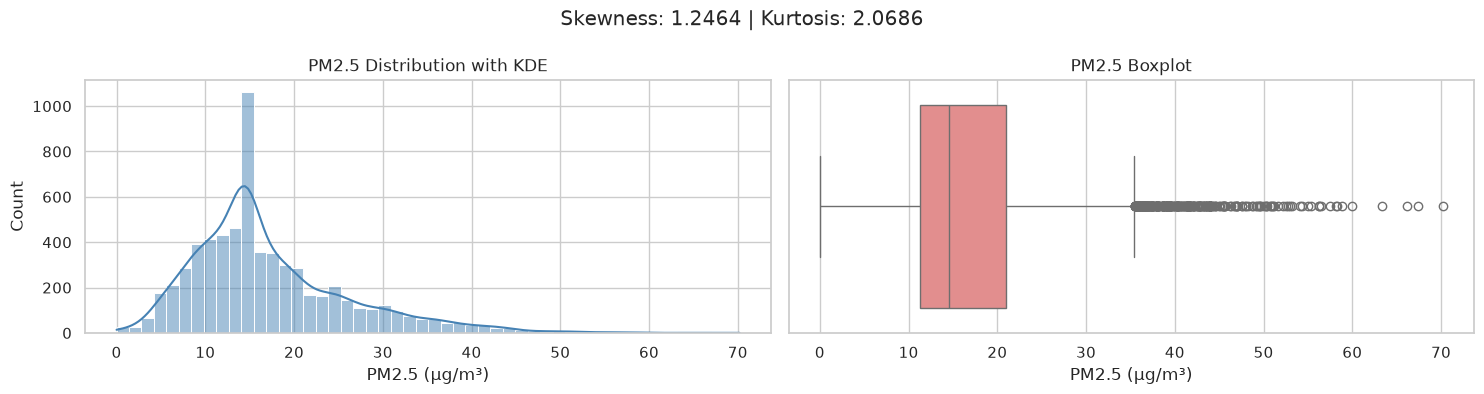

In [67]:
print(y.describe())
print(f"\nSkewness: {y.skew():.4f} | Kurtosis: {y.kurtosis():.4f}")

# Also useful to visualize the Data Distribution using a Boxplot
#===== the boxplot helps in identifying the presence of extreme outliers
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
sns.histplot(y, kde=True, bins=50, ax=axes[0], color='steelblue')
axes[0].set_title('PM2.5 Distribution with KDE')
axes[0].set_xlabel('PM2.5 (µg/m³)')

sns.boxplot(x=y, ax=axes[1], color='lightcoral')
axes[1].set_title('PM2.5 Boxplot')
axes[1].set_xlabel('PM2.5 (µg/m³)')
plt.suptitle(f"Skewness: {y.skew():.4f} | Kurtosis: {y.kurtosis():.4f}")
plt.tight_layout()
plt.show()

- On a purely mathematical level, it may be tempting to remove the outliers (e.g avoe 100 PM.2.5), however, in real-world scenarios these are accurate readings based on Nairobi transport systems, poor management of solid minicipal waste, or biomass fuel burning. Road transport alone is responsible for a significant portion of PM2.5 emissions due to a large and aged vehicle fleet. These sources produce transient, localized spikes - such as rush-hour traffic jams or open-air waste burning - that drive PM2.5 well over 100. 
Therefore, we keep the high values intact. 
- However, since time series models like AR and ARMA assume that the underlying data and its residuals are normally distributed with constant variance, our skewed data will make it hard for the models to predict extreme peaks. To solve this, we can apply a logarithmic transformation (np.log1p(y)) or a Box-Cox transformation to the y dataframe. 
    - This will compress the long tail, pull the skewness closer to 0, stabilize the variance, and make the series much easier for the autoregressive algorithm to model. We then simply inverse-transform the predictions back to the original scale after forecasting.

### 2. Time Series Roll (Rolling Mean & Std)
- Helps reveal the trend direction and volatility changes (heteroscedasticity).

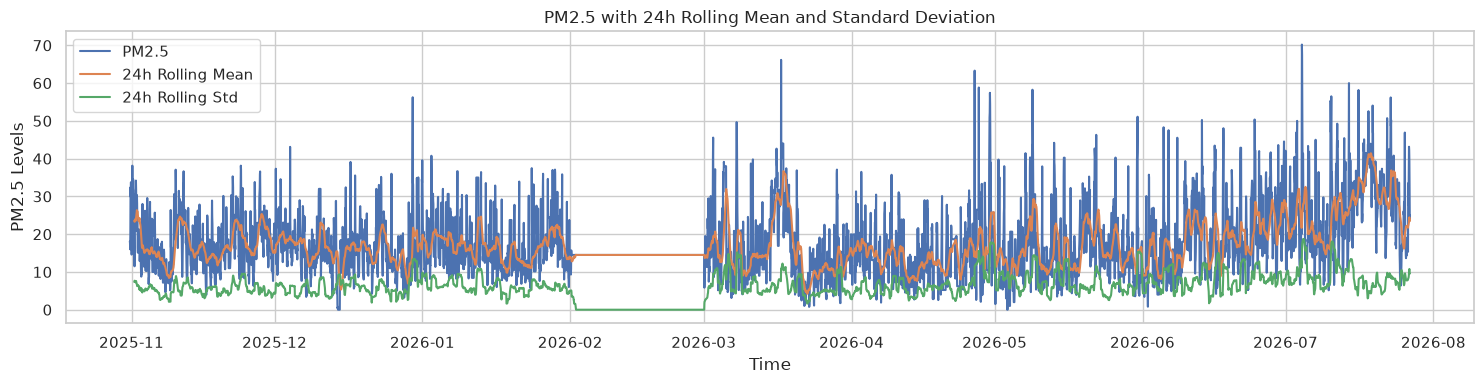

In [68]:
df_roll = pd.DataFrame({
    'PM2.5': y,
    '24h Rolling Mean': y.rolling(24).mean(),
    '24h Rolling Std': y.rolling(24).std()
})

fig, ax = plt.subplots(figsize=(15,4))
sns.lineplot(data=df_roll, ax=ax, dashes=False)
ax.set_title('PM2.5 with 24h Rolling Mean and Standard Deviation')
ax.set_xlabel('Time')
ax.set_ylabel('PM2.5 Levels')
plt.tight_layout()
plt.show()


               P2
count  912.000000
mean    28.547006
std      5.824592
min      6.000000
25%     29.966667
50%     29.966667
75%     29.966667
max     69.596429
P2       
29.966667    668
17.888235      3
17.375000      2
37.861538      2
14.650000      2
23.960526      1
20.476923      1
16.936667      1
23.996154      1
36.303125      1
41.857143      1
27.855882      1
25.325000      1
28.943333      1
22.850000      1
26.440000      1
24.663889      1
16.263158      1
17.738462      1
18.175000      1
22.293333      1
22.272222      1
32.437500      1
31.780000      1
33.697500      1
34.781250      1
38.486667      1
43.552308      1
37.468750      1
17.763333      1
Name: count, dtype: int64
Duplicate timestamps: 0


<Axes: title={'center': 'February–March: readings before cleaning'}, xlabel='timestamp'>

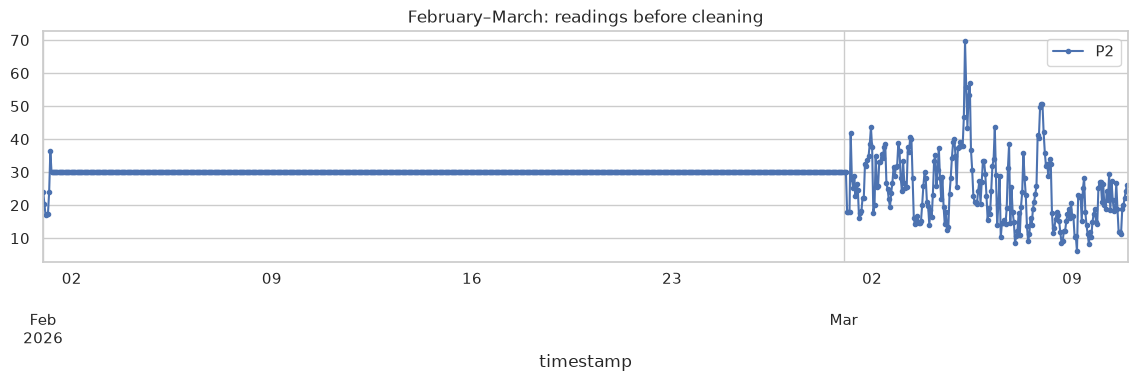

In [69]:
feb_mar = df.loc["2026-02-01":"2026-03-10"]
print(feb_mar.describe())
print(feb_mar.value_counts(dropna=False).head(30))
print("Duplicate timestamps:", y.index.duplicated().sum())

feb_mar.plot(
    figsize=(14, 3),
    marker=".",
    title="February–March: readings before cleaning"
)

### 3. Seasonal Decomposition 
- Separates trend, seasonality (daily cycle), and residual noise — critical for ARMA model design.


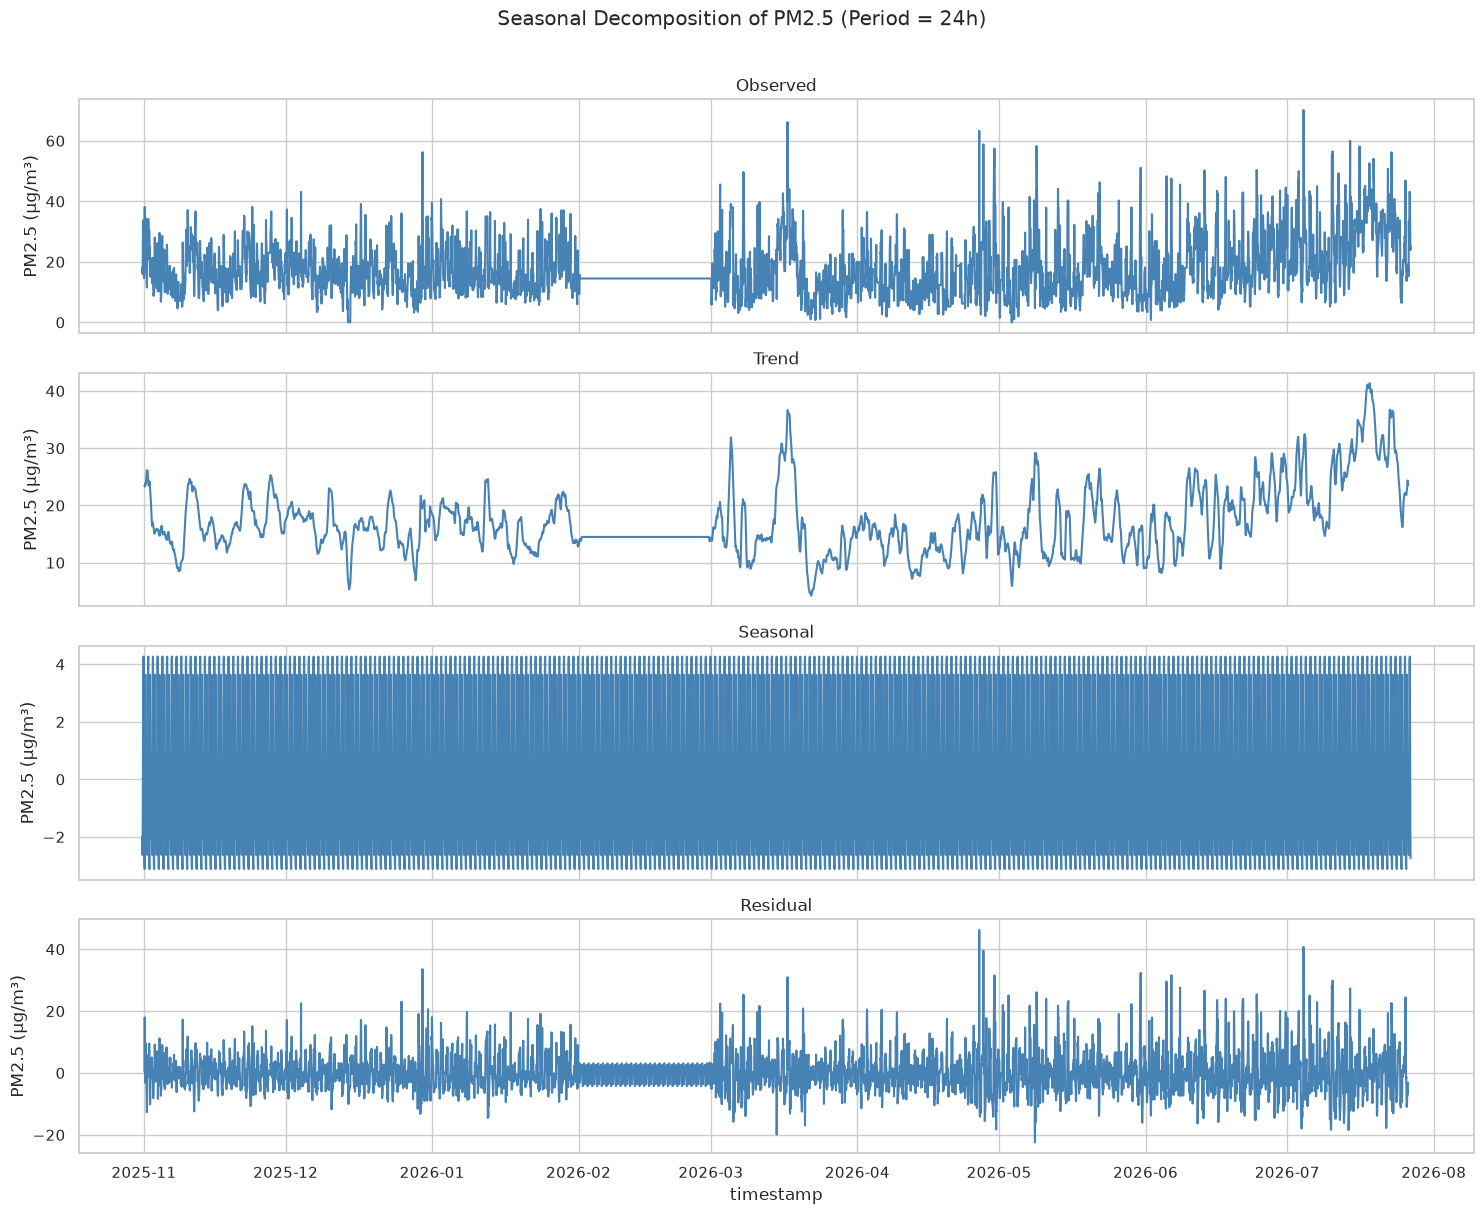

In [70]:
from statsmodels.tsa.seasonal import seasonal_decompose

result = seasonal_decompose(y, model='additive', period=24)

decomp_df = pd.DataFrame({
    'Observed': result.observed,
    'Trend':    result.trend,
    'Seasonal': result.seasonal,
    'Residual': result.resid
})

fig, axes = plt.subplots(4, 1, figsize=(15, 12), sharex=True)
for ax, col in zip(axes, decomp_df.columns):
    sns.lineplot(data=decomp_df[col], ax=ax, color='steelblue')
    ax.set_title(col)
    ax.set_ylabel('PM2.5 (µg/m³)')

plt.suptitle('Seasonal Decomposition of PM2.5 (Period = 24h)', y=1.01)
plt.tight_layout()
plt.show()


### 4. Hourly & Monthly Patterns 
- Reveals daily pollution peak hours (e.g., morning rush, evening cooking) and seasonal trends.



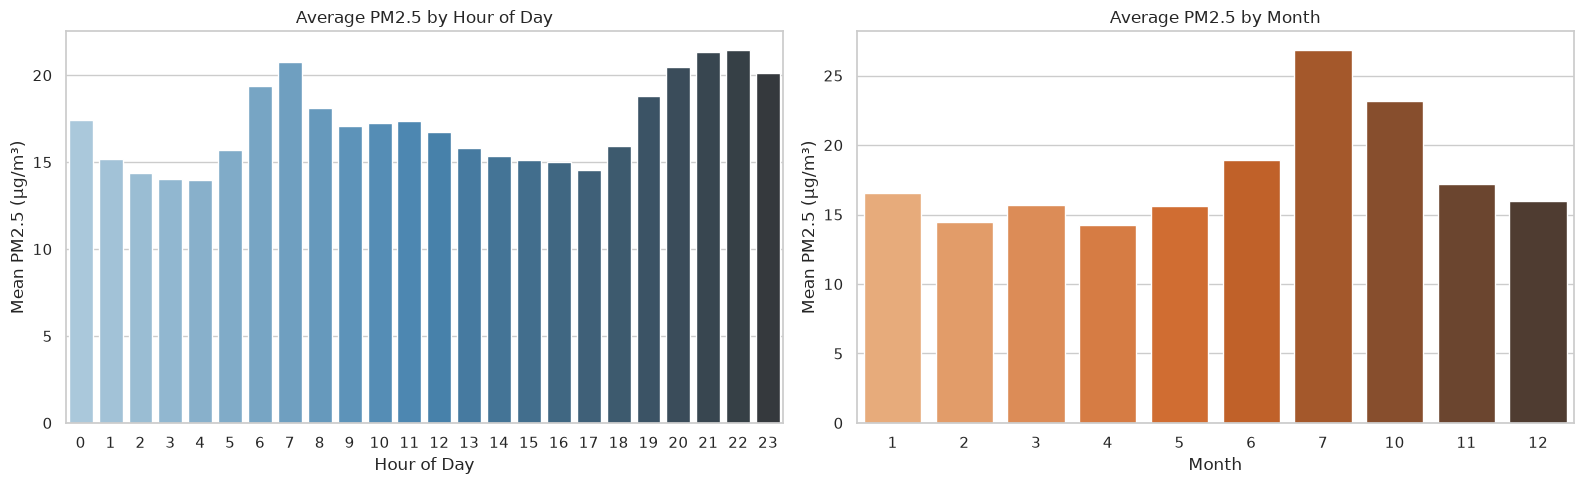

In [71]:
df_patterns = pd.DataFrame({
    'PM2.5': y,
    'Hour':  y.index.hour,
    'Month': y.index.month
})

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Average PM2.5 by hour
sns.barplot(data=df_patterns, x='Hour', y='PM2.5', estimator='mean',
            errorbar=None, palette='Blues_d', ax=axes[0])
axes[0].set_title('Average PM2.5 by Hour of Day')
axes[0].set_xlabel('Hour of Day')
axes[0].set_ylabel('Mean PM2.5 (µg/m³)')

# Average PM2.5 by month
sns.barplot(data=df_patterns, x='Month', y='PM2.5', estimator='mean',
            errorbar=None, palette='Oranges_d', ax=axes[1])
axes[1].set_title('Average PM2.5 by Month')
axes[1].set_xlabel('Month')
axes[1].set_ylabel('Mean PM2.5 (µg/m³)')

plt.tight_layout()
plt.show()


### 5. ACF & PACF Plots (most critical for AR/ARMA) 
- ACF tells you the MA order; PACF tells you the AR order for your ARMA model.
- Autocorrelation Analysis
    - Time-series data often exhibits autocorrelation, where an observation at one point in time is correlated with observations at previous points. We use Autocorrelation Function (ACF) and Partial Autocorrelation Function (PACF) plots to analyze these relationships.
        - ACF Plot: Shows the correlation of the time series with its own lagged values. The slow decay in our ACF plot suggests a strong autoregressive component.
        - PACF Plot: Shows the correlation between an observation and its lagged values after removing the effects of the intervening lags. The sharp drop-off in the PACF plot helps in determining the order of the autoregressive (AR) part of our model.


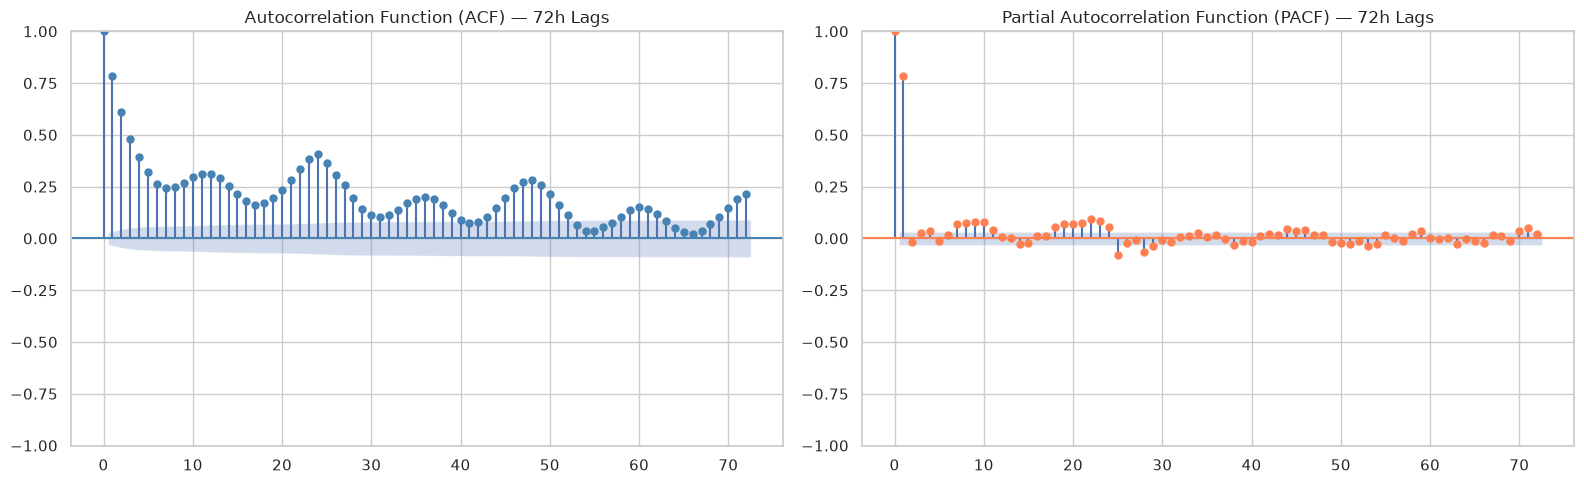

In [61]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

sns.set_theme(style='whitegrid')   # Apply Seaborn styling to statsmodels plots

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
plot_acf(y, lags=72, ax=axes[0], color='steelblue')
plot_pacf(y, lags=72, ax=axes[1], color='coral')

axes[0].set_title('Autocorrelation Function (ACF) — 72h Lags')
axes[1].set_title('Partial Autocorrelation Function (PACF) — 72h Lags')

plt.tight_layout()
plt.show()


- ACF shows a strong auto correlation. 



#### Split 

- For our final modeling phase, we define a specific training and testing period. The model will be trained on data from October 2018 and tested on its ability to forecast for the first day of November 2018. This chronological split is essential for validating a time-series model's out-of-sample performance.


In [ ]:
y_train = y.loc['10-2018']
y_test = y.loc['11-01-2018']



#### Baseline Model

- A baseline model provides a benchmark against which we can measure the performance of our more sophisticated models. A common and effective baseline for time-series forecasting is the persistence model, where the prediction for the next time step is simply the value of the current time step. We calculate the MAE for this naive forecast.

In [ ]:
y_train_mean = y_train.mean()
y_pred_baseline = [y_train_mean]* len(y_train)
mae_baseline = mean_absolute_error(y_train , y_pred_baseline)
print("Mean P2 Reading:", round(y_train_mean, 2))
print("Baseline MAE:", round(mae_baseline, 2))

## 4.0 Modelling  


- Our modeling strategy is iterative. We begin with a simple baseline and progressively build more complex models, evaluating each for its predictive accuracy. The primary evaluation metric is the Mean Absolute Error (MAE), which measures the average magnitude of the errors in a set of predictions, without considering their direction.

### 4.1 Model 1: Simple Linear Regression

- Our first model uses a simple linear regression approach. The key feature is the PM2.5 value from the previous hour (P2.L1). The hypothesis is that the current air quality is strongly dependent on the air quality of the recent past. While overly simplistic for complex time-series dynamics, it serves as a better-than-naive baseline.

In [ ]:
df = y.to_frame()
df['P2.L1'] = df['P2'].shift(1)
df.dropna(inplace=True)

cutoff = int(len(df) * 0.8)

X_train = df.iloc[:cutoff].drop(columns='P2')
y_train_lr = df.iloc[:cutoff]['P2']
X_test = df.iloc[cutoff:].drop(columns='P2')
y_test_lr = df.iloc[cutoff:]['P2']

In [ ]:
model_lr = LinearRegression()
model_lr.fit(X_train, y_train_lr)

training_mae_lr = mean_absolute_error(y_train_lr, model_lr.predict(X_train))
test_mae_lr = mean_absolute_error(y_test_lr, model_lr.predict(X_test))

print("Linear Regression Training MAE:", round(training_mae_lr, 2))
print("Linear Regression Test MAE:", round(test_mae_lr, 2))



### 4.2. Model 2: Autoregressive (AR) Model 
- An Autoregressive (AR) model is a more formal time-series model that regresses a value on its own past values. The order of the AR model, p, determines how many previous (lagged) time steps are included. Based on our PACF plot, which showed significant correlations up to approximately 24-26 hours, we select p=26 for this model.

In [ ]:
model_ar = AutoReg(y_train, lags=26).fit()
y_pred_ar = model_ar.predict().dropna()
training_mae_ar = mean_absolute_error(y_train.iloc[26:], y_pred_ar)
print("AR Model Training MAE:", training_mae_ar)

### 4.3. Model 3: ARMA Model with Hyperparameter Tuning 

- The Autoregressive Moving Average (ARMA) model is an even more powerful tool. It combines two components:
    - Autoregressive (AR) part (p): Models the relationship between an observation and a number of lagged observations.
    - Moving Average (MA) part (q): Models the relationship between an observation and the residual error from a moving average model applied to lagged observations.
- Finding the optimal values for the hyperparameters p and q is critical for model performance. We conduct a grid search, systematically training and evaluating ARMA models with various combinations of p and q to find the combination that yields the lowest training MAE.

In [ ]:
p_params = range(0,25,8)
q_params = range(0,3,1)

In [ ]:
# Create dictionary to store MAEs
mae_grid = dict()
# Outer loop: Iterate through possible values for `p`
for p in p_params:
    # Create key-value pair in dict. Key is `p`, value is empty list.
    mae_grid[p] = list()
    # Inner loop: Iterate through possible values for `q`
    for q in q_params:
        # Combination of hyperparameters for model
        order = (p, 0, q)
        # Note start time
        start_time = time.time()
        # Train model
        model = ARIMA(y_train,order=order).fit()
        # Calculate model training time
        elapsed_time = round(time.time() - start_time, 2)
        print(f"Trained ARIMA {order} in {elapsed_time} seconds.")
        # Generate in-sample (training) predictions
        y_pred = model.predict()
        # Calculate training MAE
        mae = mean_absolute_error(y_train,y_pred)
        # Append MAE to list in dictionary
        mae_grid[p].append(mae)

print()
print(mae_grid)

- The results of our grid search are best visualized using a heatmap. This allows us to quickly identify the (p, q) combination that minimizes the MAE. Based on the heatmap, we select the optimal hyperparameters for our final model, balancing performance with computational efficiency.


In [ ]:
mae_df = pd.DataFrame(mae_grid)
mae_df.round(4)

In [ ]:


sns.heatmap(mae_df,cmap='Blues')
plt.xlabel("p Values")
plt.ylabel("q Values")
plt.title("ARMA Grid Search (Criterion MAE)");



## 5.0 Final Model Evaluation

- Based on the grid search, an ARMA(8,1) model appears to offer a good balance of accuracy and computational cost. We proceed with this model for our final evaluation.


### Residual Analysis
- Before final evaluation, we examine the model's residuals (the differences between predicted and actual values). An ideal model will have residuals that are randomly distributed around zero, with no discernible patterns. The diagnostic plots for our chosen ARMA(8,1) model confirm that the residuals approximate white noise, indicating a good model fit.


In [ ]:
final_model = ARIMA(y_train, order=(8, 0, 1)).fit()
fig, ax = plt.subplots(figsize=(15, 12))
final_model.plot_diagnostics(fig=fig);

### Walk-Forward Validation
- The most rigorous method for evaluating a time-series model is walk-forward validation (WFV). In this process, the model makes a one-step-ahead forecast, then the actual observation for that step is added to the training data, and the model is re-trained before making the next forecast. This simulates a real-world scenario where the model continuously learns as new data becomes available. We perform WFV on our entire test set.

In [ ]:


# Walk-forward validation for ARMA(8,1)
preds = []
history = y_train.copy()
for i in range(len(y_test)):
    model = ARIMA(history, order=(8, 0, 1)).fit()
    next_pred = model.forecast()
    preds.append(next_pred.iloc[0])
    # Append the actual observed value to history for next step
    history = pd.concat([history, pd.Series(y_test.iloc[i], index=[y_test.index[i]])])

# Create a Series with the same index as y_test
y_pred_wfv = pd.Series(preds, index=y_test.index)



### Key Findings & Results
- The walk-forward validation provides the most realistic estimate of the model's performance on unseen data. Our final ARMA(8,1) model achieves a significantly lower Mean Absolute Error than the baseline, demonstrating its effectiveness.


In [ ]:
test_mae = mean_absolute_error(y_test, y_pred_wfv)
print("Test MAE (Walk-Forward Validation):", round(test_mae, 2))

- To visualize the model's performance, we plot its predictions against the actual PM2.5 values for the test period. The plot shows that our model's predictions closely track the true values, capturing the fluctuations in air quality with high fidelity.


In [ ]:
df_predictions = pd.DataFrame(
    {"y_test":y_test , 'y_pred_wfv': y_pred_wfv}
)

fig = px.line(df_predictions, labels={"value": "PM2.5", "timestamp": "Time"})
fig.update_layout(title_text="Nairobi PM2.5 Forecast vs. Actuals", yaxis_title="PM2.5")
fig.show()


## Business Implications & Recommendations

- The successful development of this ARMA model has direct and valuable implications:
    - Public Health: The model can serve as the engine for a public health alert system. By accurately forecasting PM2.5 levels an hour in advance, authorities can issue warnings to the public, especially vulnerable populations, allowing them to take protective measures like staying indoors or wearing masks.
    - Environmental Policy: Consistent, accurate air quality data and forecasts can help policymakers understand pollution patterns, identify sources, and evaluate the effectiveness of environmental interventions.
    - Scalability: The methodology developed in this project is scalable and can be applied to data from other sensors across Nairobi or in other cities, creating a comprehensive air quality monitoring and forecasting network.
- Recommendation: We recommend the deployment of the ARMA(8,1) model into a production environment to provide real-time hourly forecasts for PM2.5 levels at the sensor location.
Future Work & Next Steps
- While the current model is robust, there are several avenues for future improvement:
    - Multivariate Models: Incorporate other relevant variables, such as weather data (temperature, humidity, wind speed) or traffic data, by using more advanced models like SARIMAX or vector autoregression (VAR).
    - Advanced Architectures: Explore machine learning and deep learning models, such as LSTMs (Long Short-Term Memory networks), which are specifically designed for sequence prediction and may capture more complex, non-linear patterns.
    - Expanded Geographic Scope: Apply the modeling process to other sensor sites to build a city-wide forecasting system.

## Conclusion
- This project successfully demonstrates the power of time-series analysis in addressing a critical public health issue. By systematically progressing from data wrangling to advanced modeling and rigorous evaluation, we have developed a reliable ARMA model capable of forecasting hourly PM2.5 concentrations in Nairobi. The resulting tool not only achieves strong technical performance but also offers tangible value for public health and environmental management. The framework established here provides a solid foundation for future enhancements and broader application.
